# Vision-Language Model Inference with MedGemma

This notebook demonstrates how to use a vision-language model (VLM) on brain MRI images. It covers model access, local model loading, prompt-based inference, and a small-batch evaluation loop.

> **Educational-use note:** This notebook is for teaching VLM workflows only. It is not a clinical validation study and must not be used for diagnosis or medical decision-making.

## Table of contents

1. [Imports and shared configuration](#1-imports-and-shared-configuration)  
2. [Hugging Face model access methods](#2-hugging-face-model-access-methods)  
3. [Download MedGemma](#3-download-medgemma)  
4. [Load MedGemma with `pipeline()`](#4-load-medgemma-with-pipeline)  
5. [Helper functions](#5-helper-functions)  
6. [Download and prepare the MRI dataset](#6-download-and-prepare-the-mri-dataset)  
7. [Text-only inference](#7-text-only-inference)  
8. [Image-and-text inference](#8-image-and-text-inference)  
9. [Small-batch evaluation](#9-small-batch-evaluation)  
10. [Inspect and save results](#10-inspect-and-save-results)  
11. [Optional appendix: lower-level Auto classes](#11-optional-appendix-lower-level-auto-classes)  
12. [Limitations and takeaways](#12-limitations-and-takeaways)


## Learning objectives
By the end of this notebook, you should be able to:

1. Choose an access method for your model.
2. Download or load the model.
3. Prepare image and text inputs.
4. Do inference with your model.
5. Parse the model response into labels.
6. Evaluate a small sample of predictions.


## 1. Imports and shared configuration

Complete the [shared course setup](../../README.md#environment-setup), using the root [requirements.txt](../../requirements.txt), before running this notebook. Select that environment as the notebook kernel. Model access is explained in section 3.

All constants used later in the notebook are defined here:

What these configuration settings do:

- `TEXT_MAX_NEW_TOKENS = 200` limits how many new tokens the model can generate for text-only responses. A higher value allows longer answers, while a lower value keeps outputs shorter and faster.

- `VISION_MAX_NEW_TOKENS = 32` limits how many new tokens the model can generate when responding to an image-and-text prompt. This is intentionally shorter because the classification task should produce a concise answer.

- `MAX_DATASET_ROWS = 12` controls how many MRI examples are loaded from the dataset for the demo.

- `RANDOM_SEED = 42` makes random operations, such as sampling dataset rows, reproducible.

In [15]:
from pathlib import Path
import json
import random
import re
import warnings
from tqdm.std import TqdmWarning
import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import torch
from huggingface_hub import get_token, snapshot_download
from PIL import Image
from transformers import pipeline
from transformers.utils import logging as hf_logging
from transformers import GenerationConfig

# Keep notebook output clean by hiding non-critical warnings.
hf_logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=TqdmWarning)

# Hugging Face model and local storage path.
MODEL_ID = "google/medgemma-1.5-4b-it"
LOCAL_MODEL_DIR = "medgemma"

# Dataset used in the educational demo.
KAGGLE_DATASET = "navoneel/brain-mri-images-for-brain-tumor-detection"

# Keep the demo small enough to run during a class session.
TEXT_MAX_NEW_TOKENS = 200
VISION_MAX_NEW_TOKENS = 32
MAX_DATASET_ROWS = 12
RANDOM_SEED = 42

random.seed(RANDOM_SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.bfloat16 if device == "cuda" else torch.float32

print("Model ID:", MODEL_ID)
print("Local model directory:", LOCAL_MODEL_DIR)
print("Device:", device)
print("Torch dtype:", dtype)

if device == "cpu":
    print("Warning: MedGemma is large. CPU inference may be very slow or may not fit in memory.")


Model ID: google/medgemma-1.5-4b-it
Local model directory: medgemma
Device: cuda
Torch dtype: torch.bfloat16


## 2. Hugging Face model access methods

The following tools work at different levels of control. For the BwUniCluster, a typical workflow is:

1. **Download once** with `snapshot_download()`.
2. **Load offline** with `pipeline()` or `*.from_pretrained()`.
3. **Run inference** with `pipeline()` or with separate processor and model objects.

| Tool | What it does | Online/offline use |
|---|---|---|
| `snapshot_download()` | Downloads model repository files into a local cache or folder. | Use it once with internet access before offline jobs. |
| `pipeline("image-text-to-text", model=...)` | Builds an end-to-end object for preprocessing, model inference, generation, and output formatting. | Use a Hub model ID online, or a local folder offline. |
| `from_pretrained(...)` | Loads a saved component such as a model, processor, or tokenizer. | Use a Hub model ID online, or a local folder/cache offline. |
| `AutoProcessor.from_pretrained(...)` | Loads the processor that formats prompts, prepares image/text inputs, and decodes outputs. | Use the same Hub model ID or local folder as the model. |
| `AutoModelForImageTextToText.from_pretrained(...)` | Loads the model architecture and weights for image-text-to-text generation. | Use a Hub model ID online, or a local folder/cache offline. |
| `AutoTokenizer.from_pretrained(...)` | Loads the text tokenizer that converts text to token IDs. | Use it directly for text-only workflows or advanced control. |

For this introductory notebook, we use `snapshot_download()` once and then use the high-level `pipeline()` interface for the main workflow.

## 3. Download MedGemma
MedGemma is a collection of Gemma 3 variants that are **trained for performance on medical text and image comprehension**. Developers can use MedGemma to accelerate building healthcare-based AI applications. MedGemma currently comes in three variants: a 4B multimodal version and 27B text-only and multimodal versions.


MedGemma is a **gated Hugging Face model**. Before running the following cell and downloading medgemma:

1. Create or sign in to a Hugging Face account.
2. Open the specific MedGemma model page used by this notebook and accept the usage terms:
    - <https://huggingface.co/google/medgemma-1.5-4b-it>
3. Authenticate this environment with a Hugging Face access token. For example:
   - Run `hf auth login` in a terminal.
   - Or set the `HF_TOKEN` environment variable.

References:

- CLI login / authentication:  
  <https://huggingface.co/docs/huggingface_hub/en/guides/cli>
- Access token creation:  
  <https://huggingface.co/docs/hub/security-tokens>

In [2]:
hf_token = get_token()
if hf_token is None:
    print(
        "No Hugging Face token was found. If this gated model fails to download, "
        "run `hf auth login` in a terminal or set the HF_TOKEN environment variable."
    )
else:
    print("Hugging Face token found.")

local_model_path = snapshot_download(
    repo_id=MODEL_ID,
    local_dir=LOCAL_MODEL_DIR,
    token=True,  # Uses your saved Hugging Face token or HF_TOKEN for gated access.
)

print("Model downloaded to:", Path(local_model_path).resolve())


Hugging Face token found.


## 4. Load MedGemma with `pipeline()`
This is the first cell that actually loads the model for inference. It uses the local folder created by `snapshot_download()` instead of asking Hugging Face to resolve the model again.


In [3]:
pipe = pipeline(
    task="image-text-to-text",
    model=LOCAL_MODEL_DIR,
    torch_dtype="auto",
    device_map="auto",
)

print("Pipeline ready.")


Pipeline ready.


## 5. Helper functions
These small helpers keep the inference and evaluation cells readable:

- `extract_generated_text()` extracts the generated text.
- `parse_binary_label()` extracts a simple `tumor` / `no_tumor` prediction from generated text.
- `make_image_message()` builds the message format used by image-text-to-text models.
- `run_vlm_on_image()` wraps a single image inference call.


In [ ]:
def extract_generated_text(output_obj):
    """Extract the assistant text from the MedGemma pipeline output."""
    return output_obj[0]["generated_text"][-1]["content"].strip()


def parse_binary_label(text):
    """Parse the label line from a generated answer."""
    first_line = text.strip().splitlines()[0].lower()
    label = first_line.replace("label:", "").strip()

    if label == "tumor":
        return "tumor"
    if label == "no_tumor":
        return "no_tumor"

    return "unparsed"


def make_image_message(image, prompt):
    """Create the chat-style message expected by image-text-to-text pipelines."""
    return [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": prompt},
            ],
        }
    ]


def run_vlm_on_image(image, prompt, max_new_tokens=VISION_MAX_NEW_TOKENS):
    """Run one image-text prompt through the loaded MedGemma pipeline."""
    messages = make_image_message(image, prompt)

    output = pipe(
        text=messages,
        generate_kwargs={
            "max_new_tokens": max_new_tokens,
            "do_sample": False,
        },
    )

    return extract_generated_text(output)


## 6. Download and prepare the MRI dataset

**Dataset source:** [Brain MRI Images for Brain Tumor Detection](https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection), published on Kaggle by `navoneel`. This is an external dataset; the course author does not claim ownership. Its images are not relicensed under the course's Apache 2.0 license.

This cell downloads the dataset and creates a small dataframe with:

- `image_path`: the local path to an image,
- `true_label`: the folder-derived label, either `tumor` or `no_tumor`.


In [ ]:
dataset_root = Path(kagglehub.dataset_download(KAGGLE_DATASET))
print("Dataset root:", dataset_root)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

label_folders = {
    "yes": "tumor",
    "no": "no_tumor",
}

records = []

for folder_name, label in label_folders.items():
    folder = next(dataset_root.rglob(folder_name))

    image_paths = [
        p for p in sorted(folder.rglob("*"))
        if p.suffix.lower() in IMAGE_EXTS
    ]

    for image_path in image_paths:
        records.append({
            "image_path": str(image_path),
            "true_label": label,
        })

df = pd.DataFrame(records)
print(f'The original Datset has {len(df)} rows.')

rows_per_class = MAX_DATASET_ROWS // len(label_folders)

df = (
    df.groupby("true_label", group_keys=False)
    .sample(n=rows_per_class, random_state=RANDOM_SEED)
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

print("Rows found after sampling:", len(df))
print(df["true_label"].value_counts())
df

## 7. Text-only inference
A VLM can often accept text-only prompts as well as image-and-text prompts. This short cell shows the same pipeline answering an educational text prompt.


In [16]:
text_prompt = (
    "You are a medical AI assistant for education. "
    "In 3 short bullet points, explain: "
    "(1) what a brain tumor is, "
    "(2) why MRI can help detect one, and "
    "(3) why imaging alone does not replace diagnosis by a qualified clinician. "
    "Avoid personalized medical advice."
)

text_messages = [
    {
        "role": "user",
        "content": [{"type": "text", "text": text_prompt}],
    }
]

text_output = pipe(
    text=text_messages,
    generate_kwargs={
        "max_new_tokens": TEXT_MAX_NEW_TOKENS,
        "do_sample": False,
    },
)

print(extract_generated_text(text_output))


Here's a brief explanation:

*   **What a brain tumor is:** A brain tumor is an abnormal mass of tissue, often made of cells that grow uncontrollably, that forms within the brain. These tumors can be benign (non-cancerous) or malignant (cancerous), and they can vary greatly in size and location.
*   **Why MRI helps detect one:** Magnetic Resonance Imaging (MRI) uses strong magnetic fields and radio waves to create detailed images of the brain's soft tissues. This allows doctors to visualize tumors, even small ones, and see their size, location, and relationship to surrounding structures, aiding in detection.
*   **Why imaging alone isn't enough:** While MRI is a powerful diagnostic tool, it's just one part of the process. A qualified clinician (like a neurologist or neurosurgeon) needs to interpret the MRI findings in the context of a patient's symptoms, medical history, and other tests (like CT scans or


## 8. Image-and-text inference
First, display one sampled MRI image with its folder-derived label.


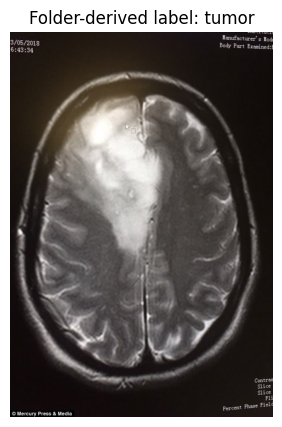

In [7]:
if df.empty:
    raise ValueError("No images were found. Check the Kaggle dataset download and folder structure.")

sample_idx = 0
sample_row = df.iloc[sample_idx]
sample_image = Image.open(sample_row["image_path"]).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.title(f"Folder-derived label: {sample_row['true_label']}")
plt.axis("off")
plt.show()


Now ask MedGemma to classify the image with a strict response format. The response is still generated text, so the parsed label is only a demonstration output.


In [8]:
classification_prompt_with_reason = (
    "You are doing an educational binary image classification task on a brain MRI.\n\n"
    "Decide whether the image more likely shows:\n"
    "- tumor\n"
    "- no_tumor\n\n"
    "Return exactly in this format:\n"
    "label: <tumor_or_no_tumor>\n"
    "reason: <one short sentence>"
)

sample_text = run_vlm_on_image(
    sample_image,
    classification_prompt_with_reason,
    max_new_tokens=VISION_MAX_NEW_TOKENS,
)

print(sample_text)
print("Parsed label:", parse_binary_label(sample_text))


label: tumor
reason: there is a large area of increased density in the right hemisphere of the brain.
Parsed label: tumor


## 9. Small-batch evaluation
This cell loops over the sampled dataframe and runs the same classification prompt on each image. For every row, it stores:

- the image path,
- the folder-derived label,
- the parsed predicted label,
- and the raw model output.

The `try`/`except` block keeps the class demo from stopping completely if one image causes an inference error.


In [9]:
classification_prompt = (
    "You are doing an educational binary image classification task on a brain MRI.\n\n"
    "Decide whether the image more likely shows:\n"
    "- tumor\n"
    "- no_tumor\n\n"
    "Return exactly one line in one of these forms:\n"
    "label: tumor\n"
    "label: no_tumor"
)

results = []

for i, row in df.iterrows():
    img = Image.open(row["image_path"]).convert("RGB")

    try:
        raw_text = run_vlm_on_image(
            img,
            classification_prompt,
            max_new_tokens=8,
        )
        pred_label = parse_binary_label(raw_text)
    except Exception as e:
        raw_text = f"ERROR: {type(e).__name__}: {e}"
        pred_label = "error"

    results.append(
        {
            "image_path": row["image_path"],
            "true_label": row["true_label"],
            "pred_label": pred_label,
            "raw_output": raw_text,
        }
    )

    print(f"Processed {i + 1}/{len(df)}")

results_df = pd.DataFrame(results)
display(results_df.head())


Processed 1/12
Processed 2/12
Processed 3/12
Processed 4/12
Processed 5/12
Processed 6/12
Processed 7/12
Processed 8/12
Processed 9/12
Processed 10/12
Processed 11/12
Processed 12/12


## 10. Inspect and save results
The next cell computes a simple accuracy score and a confusion table.


In [10]:
eval_df = results_df.copy()
eval_df["is_correct"] = eval_df["true_label"] == eval_df["pred_label"]

accuracy = eval_df["is_correct"].mean()

print(f"Rows evaluated: {len(eval_df)}")
print(f"Accuracy: {accuracy:.3f}")

confusion = pd.crosstab(
    eval_df["true_label"],
    eval_df["pred_label"],
    rownames=["true_label"],
    colnames=["pred_label"],
    dropna=False,
)

display(confusion)


Rows evaluated: 12
Accuracy: 0.833


pred_label,no_tumor,tumor
true_label,,
no_tumor,4,2
tumor,0,6


Finally, save the raw predictions to a CSV file. Keeping the raw generated text makes it easier to inspect whether errors came from model behavior, output formatting, or parsing logic.


In [ ]:
output_path = Path("medgemma_brain_mri_predictions.csv")
results_df.to_csv(output_path, index=False)

print("Saved:", output_path.resolve())


## 11. Optional appendix: lower-level Auto classes
The main notebook uses `pipeline()` because it is the clearest first interface for beginners. The optional cell below shows the lower-level workflow with `AutoProcessor` and `AutoModelForImageTextToText`.

This is switched off by default because it loads another model object and can use substantial memory. Turn it on only after the earlier cells have downloaded MedGemma and selected `sample_image`.


In [12]:
RUN_AUTOMODEL_EXAMPLE = True

if RUN_AUTOMODEL_EXAMPLE:
    from transformers import AutoModelForImageTextToText, AutoProcessor

    processor = AutoProcessor.from_pretrained(LOCAL_MODEL_DIR)
    model = AutoModelForImageTextToText.from_pretrained(
        LOCAL_MODEL_DIR,
        torch_dtype=dtype,
        device_map="auto",
    )

    automodel_prompt = "What do you see in this brain MRI image? Answer briefly for education only."
    messages = make_image_message(sample_image, automodel_prompt)

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device, dtype=dtype)

    input_len = inputs["input_ids"].shape[-1]

    with torch.inference_mode():
        generation = model.generate(
            **inputs,
            max_new_tokens=VISION_MAX_NEW_TOKENS,
            do_sample=False,
        )

    generated_tokens = generation[0][input_len:]
    decoded = processor.decode(generated_tokens, skip_special_tokens=True)

    print(decoded)


Based on the image, I can see a large area of abnormal signal intensity in the right frontal lobe of the brain. This could represent a variety of conditions,


## 12. Limitations and takeaways
Main takeaways:

- `snapshot_download()` is useful when model files need to be available locally, especially for gated models, classrooms, or cluster workflows.
- `pipeline()` combines preprocessing, inference, generation, and output formatting into one task-specific interface.
- `AutoProcessor` and `AutoModelForImageTextToText` provide more control, but they introduce more moving parts.
- Structured prompts make generated responses easier to parse, but parsing generated text is still brittle.

Limitations:

- The evaluation sample is intentionally tiny, so the accuracy is not a reliable benchmark.
- MedGemma is a generative model; the binary label is extracted from generated text and can change with prompt wording, decoding settings, and model version.
- This notebook is for education only and should not be used for diagnosis or clinical decision-making.
